# Q08 - Multi-Agent Creative Drawing by Combining Two Patterns

Same code as `q08_code.py`. Works locally in Jupyter or on Google Colab (upload this notebook, then *Runtime -> Run all*).

In [1]:
"""Q8 - Multi-agent system that combines two drawing patterns into a new creative drawing.

Agent A owns a square spiral, Agent B owns a five-point star. Each agent builds NEW actions by
combining one action of each parent. New actions expand the action space, so the search space
grows too. Every proposal (a new state) is scored by fitness = novelty + aesthetics + inheritance.
"""
import math
import os
import random

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.collections import LineCollection

os.makedirs("images", exist_ok=True)
random.seed(2)
plt.rcParams.update({"figure.dpi": 130, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "font.size": 10})

BASE_ACTIONS = ["F", "L", "G", "C"]  # forward, turn left, grow step, change colour
NEW_ACTIONS = ["LG", "STAR", "BLEND"]  # turn+grow, star-as-one-action, blended turn
PARENT_A = [("F",), ("L", 90.0), ("G", 3.0)] * 40  # square spiral
PARENT_B = [("G", 56.0)] + [("F",), ("L", 144.0)] * 5  # five-point star


def run_turtle(program: list) -> list:
    """Execute action tokens; return line segments (x1, y1, x2, y2)."""
    x = y = heading = 0.0
    step, segs = 4.0, []
    for tok in program:
        if tok[0] == "F":
            nx, ny = x + step * math.cos(math.radians(heading)), y + step * math.sin(math.radians(heading))
            segs.append((x, y, nx, ny))
            x, y = nx, ny
        elif tok[0] in ("L", "BLEND"):
            heading += tok[1]
        elif tok[0] == "G":
            step += tok[1]
        elif tok[0] == "LG":  # combined action: turn and grow in one move
            heading, step = heading + tok[1], step + tok[2]
        elif tok[0] == "STAR":  # pattern B packed into a single new action
            sx, sy, h = x, y, heading
            for _ in range(5):
                nx, ny = sx + tok[1] * math.cos(math.radians(h)), sy + tok[1] * math.sin(math.radians(h))
                segs.append((sx, sy, nx, ny))
                sx, sy, h = nx, ny, h + 144.0
    return segs


def points_of(segs: list) -> np.ndarray:
    t = np.linspace(0, 1, 8)[:, None]
    return np.vstack([np.hstack([x1 + t * (x2 - x1), y1 + t * (y2 - y1)]) for x1, y1, x2, y2 in segs])


def raster(pts: np.ndarray, centre: np.ndarray, radius: float, n: int = 24) -> np.ndarray:
    idx = np.clip(((pts - centre) / radius + 1) / 2 * n, 0, n - 1).astype(int)
    grid = np.zeros((n, n), bool)
    grid[idx[:, 1], idx[:, 0]] = True
    return grid


def describe(segs: list) -> tuple:
    pts = points_of(segs)
    centre = pts.mean(axis=0)
    radius = np.abs(pts - centre).max() + 1e-9
    return pts, centre, radius, raster(pts, centre, radius)


def iou(a: np.ndarray, b: np.ndarray) -> float:
    return (a & b).sum() / max(1, (a | b).sum())


def aesthetics(segs: list) -> float:
    """Living-geometry style score: local symmetry + balanced coverage + levels of scale."""
    pts, centre, radius, grid = describe(segs)
    sym = 0.0
    for k in (3, 4, 5, 6, 8):
        a = 2 * math.pi / k
        rot = (pts - centre) @ np.array([[math.cos(a), math.sin(a)], [-math.sin(a), math.cos(a)]])
        sym = max(sym, iou(grid, raster(rot + centre, centre, radius)))
    coverage = grid.mean()
    lengths = np.array([math.hypot(x2 - x1, y2 - y1) for x1, y1, x2, y2 in segs])
    scales = min(1.0, lengths.std() / lengths.mean())
    return 0.5 * sym + 0.3 * (1 - min(1.0, abs(coverage - 0.3) / 0.3)) + 0.2 * scales


GRID_A, GRID_B = describe(run_turtle(PARENT_A))[3], describe(run_turtle(PARENT_B))[3]


def fitness(cand: dict) -> dict:
    segs = run_turtle(cand["program"])
    grid = describe(segs)[3]
    novelty = 1 - max(iou(grid, GRID_A), iou(grid, GRID_B))  # how far from both parents
    inherit = 1 - abs(2 * cand["share_a"] - 1)  # 1.0 when both parents contribute equally
    score = 0.4 * novelty + 0.4 * aesthetics(segs) + 0.2 * inherit
    return {**cand, "grid": grid, "novelty": novelty, "aesth": aesthetics(segs),
            "inherit": inherit, "fit": score}


def combine(op: str, p: dict) -> dict:
    """Make a new action out of one action from each parent, then repeat it n times."""
    if op == "compose":  # LG = star's turn + spiral's growth, executed as ONE action
        prog, share = [("F",), ("LG", 144.0 + p["jit"], 3.0 * p["g"])] * p["n"], 0.5
    elif op == "blend":  # BLEND = weighted mix of the two turn angles
        theta = p["alpha"] * 90.0 + (1 - p["alpha"]) * 144.0
        prog, share = [("F",), ("BLEND", theta), ("G", 3.0 * p["g"])] * p["n"], p["alpha"]
    elif op == "nest":  # STAR becomes a single action placed at every spiral corner
        prog, share = [("F",), ("L", 90.0), ("G", 3.0 * p["g"]), ("STAR", p["size"])] * p["n"], 0.6
    else:  # interleave: one spiral move, then one star move
        prog, share = [("F",), ("L", 90.0), ("G", 3.0 * p["g"]), ("F",), ("L", 144.0)] * p["n"], 0.5
    return {"op": op, "params": p, "program": prog, "share_a": share}


def random_params() -> dict:
    return {"n": random.randint(24, 70), "jit": random.uniform(-6, 6), "g": random.uniform(0.5, 1.5),
            "alpha": random.uniform(0.2, 0.8), "size": random.uniform(8, 25)}


def mutate(p: dict) -> dict:
    q = dict(p)
    key = random.choice(list(q))
    q[key] = random_params()[key] if key != "n" else max(20, q["n"] + random.randint(-10, 10))
    return q


AGENTS = {"A-spiral": ["compose", "blend", "nest"], "B-star": ["compose", "interleave", "nest"]}


def multi_agent_search(rounds: int = 6, proposals: int = 5) -> tuple:
    archive, history, all_cands = [], [], []  # archive = shared memory of new states
    best = {a: None for a in AGENTS}
    for r in range(1, rounds + 1):
        for agent, ops in AGENTS.items():
            for _ in range(proposals):
                if best[agent] and random.random() < 0.6:  # exploit: tweak own best idea
                    c = combine(best[agent]["op"], mutate(best[agent]["params"]))
                else:  # explore: brand-new combination of the two parents
                    c = combine(random.choice(ops), random_params())
                c = {**fitness(c), "agent": agent, "round": r}
                all_cands.append(c)
                if all(iou(c["grid"], g) < 0.6 for g in archive):  # a genuinely new state
                    archive.append(c["grid"])
                if best[agent] is None or c["fit"] > best[agent]["fit"]:
                    best[agent] = c
            history.append((r, agent, best[agent], len(archive)))
    return history, all_cands


print("Q8  Multi-agent creative drawing (Agent A = spiral, Agent B = star)")
L = 6
base, grown = len(BASE_ACTIONS), len(BASE_ACTIONS) + len(NEW_ACTIONS)
print(f"Action space: {base} basic actions -> {grown} after 3 combined actions")
print(f"Search space for a motif of {L} actions: {base}^{L} = {base ** L:,} -> "
      f"{grown}^{L} = {grown ** L:,} ({grown ** L / base ** L:.1f}x larger)")
history, all_cands = multi_agent_search()
print(f"{'round':>5} | {'agent':<8} | {'best operator':<13} | fitness | novelty | aesth | archive")
for r, agent, top, size in history:
    print(f"{r:>5} | {agent:<8} | {top['op']:<13} | {top['fit']:7.3f} | {top['novelty']:7.3f} |"
          f" {top['aesth']:5.3f} | {size:>7}")
ranked = sorted(all_cands, key=lambda c: -c["fit"])
winner = ranked[0]
print(f"Best drawing: {winner['op']} by {winner['agent']} (round {winner['round']}), "
      f"fitness {winner['fit']:.3f}")
print(f"Parents scored aesthetics A = {aesthetics(run_turtle(PARENT_A)):.3f}, "
      f"B = {aesthetics(run_turtle(PARENT_B)):.3f}")

# ---------------- charts ----------------
picks, seen = [], set()
for c in ranked:
    if c["op"] not in seen:
        picks.append(c)
        seen.add(c["op"])
    if len(picks) == 4:
        break
LABELS = {"compose": "compose: turn(B) + grow(A)", "blend": "blend: mixed turn angle",
          "nest": "nest: STAR at spiral corners", "interleave": "interleave: A move, B move"}
fig, axes = plt.subplots(2, 3, figsize=(11, 7.4))
panels = [("Parent A: square spiral", PARENT_A, None), ("Parent B: five-point star", PARENT_B, None)]
panels += [(f"{LABELS[c['op']]}\n{c['agent']}, fitness {c['fit']:.2f}", c["program"], c) for c in picks]
for ax, (title, prog, cand) in zip(axes.flat, panels):
    segs = np.array(run_turtle(prog))
    lines = segs.reshape(-1, 2, 2)
    colours = plt.cm.plasma(np.linspace(0.05, 0.85, len(lines))) if cand else ["#374151"] * len(lines)
    ax.add_collection(LineCollection(lines, colors=colours, linewidths=1.1))
    ax.autoscale()
    ax.set_aspect("equal")
    ax.axis("off")
    ax.set_title(title, fontsize=9.5)
fig.suptitle("Parents (top-left) and the best new drawing per combination operator", fontsize=11)
fig.tight_layout()
fig.savefig("images/q08_chart1_drawings.png")
plt.close(fig)

fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 3.9))
for agent, colour in zip(AGENTS, ["#3a6ea5", "#e76f51"]):
    rows = [(r, top["fit"]) for r, ag, top, _ in history if ag == agent]
    a1.plot([x[0] for x in rows], [x[1] for x in rows], "o-", color=colour, label=f"{agent} best so far")
a1b = a1.twinx()
a1b.bar([r for r, ag, _, _ in history if ag == "B-star"],
        [size for _, ag, _, size in history if ag == "B-star"], color="#2a9d8f", alpha=0.15)
a1b.set_ylabel("drawings in shared archive", color="#2a9d8f")
a1b.grid(False)
a1.set_zorder(a1b.get_zorder() + 1)
a1.patch.set_visible(False)
a1.set_xlabel("round")
a1.set_ylabel("fitness")
a1.set_title("Agents' fitness per round (bars = archive size)")
a1.legend(fontsize=8, loc="lower right")
lengths = np.arange(1, 9)
a2.semilogy(lengths, base ** lengths, "o-", color="#9ca3af", label=f"{base} basic actions")
a2.semilogy(lengths, grown ** lengths, "s-", color="#2a9d8f", label=f"{grown} actions (with combined)")
a2.set_xlabel("motif length (number of actions)")
a2.set_ylabel("possible drawings (log scale)")
a2.set_title("Search space growth after adding new actions")
a2.legend(fontsize=8)
fig.tight_layout()
fig.savefig("images/q08_chart2_fitness_space.png")
plt.close(fig)
print("charts saved to images/")


Q8  Multi-agent creative drawing (Agent A = spiral, Agent B = star)
Action space: 4 basic actions -> 7 after 3 combined actions
Search space for a motif of 6 actions: 4^6 = 4,096 -> 7^6 = 117,649 (28.7x larger)


round | agent    | best operator | fitness | novelty | aesth | archive
    1 | A-spiral | compose       |   0.703 |   0.732 | 0.525 |       2
    1 | B-star   | nest          |   0.616 |   0.499 | 0.641 |       3
    2 | A-spiral | compose       |   0.739 |   0.646 | 0.702 |       5
    2 | B-star   | compose       |   0.724 |   0.681 | 0.628 |       7
    3 | A-spiral | compose       |   0.779 |   0.684 | 0.763 |      10
    3 | B-star   | compose       |   0.735 |   0.677 | 0.661 |      13
    4 | A-spiral | compose       |   0.779 |   0.684 | 0.763 |      16
    4 | B-star   | compose       |   0.740 |   0.667 | 0.683 |      16
    5 | A-spiral | compose       |   0.779 |   0.684 | 0.763 |      18
    5 | B-star   | compose       |   0.749 |   0.669 | 0.703 |      20
    6 | A-spiral | compose       |   0.793 |   0.672 | 0.810 |      23
    6 | B-star   | compose       |   0.749 |   0.669 | 0.703 |      26
Best drawing: compose by A-spiral (round 6), fitness 0.793
Parents scored aes

charts saved to images/


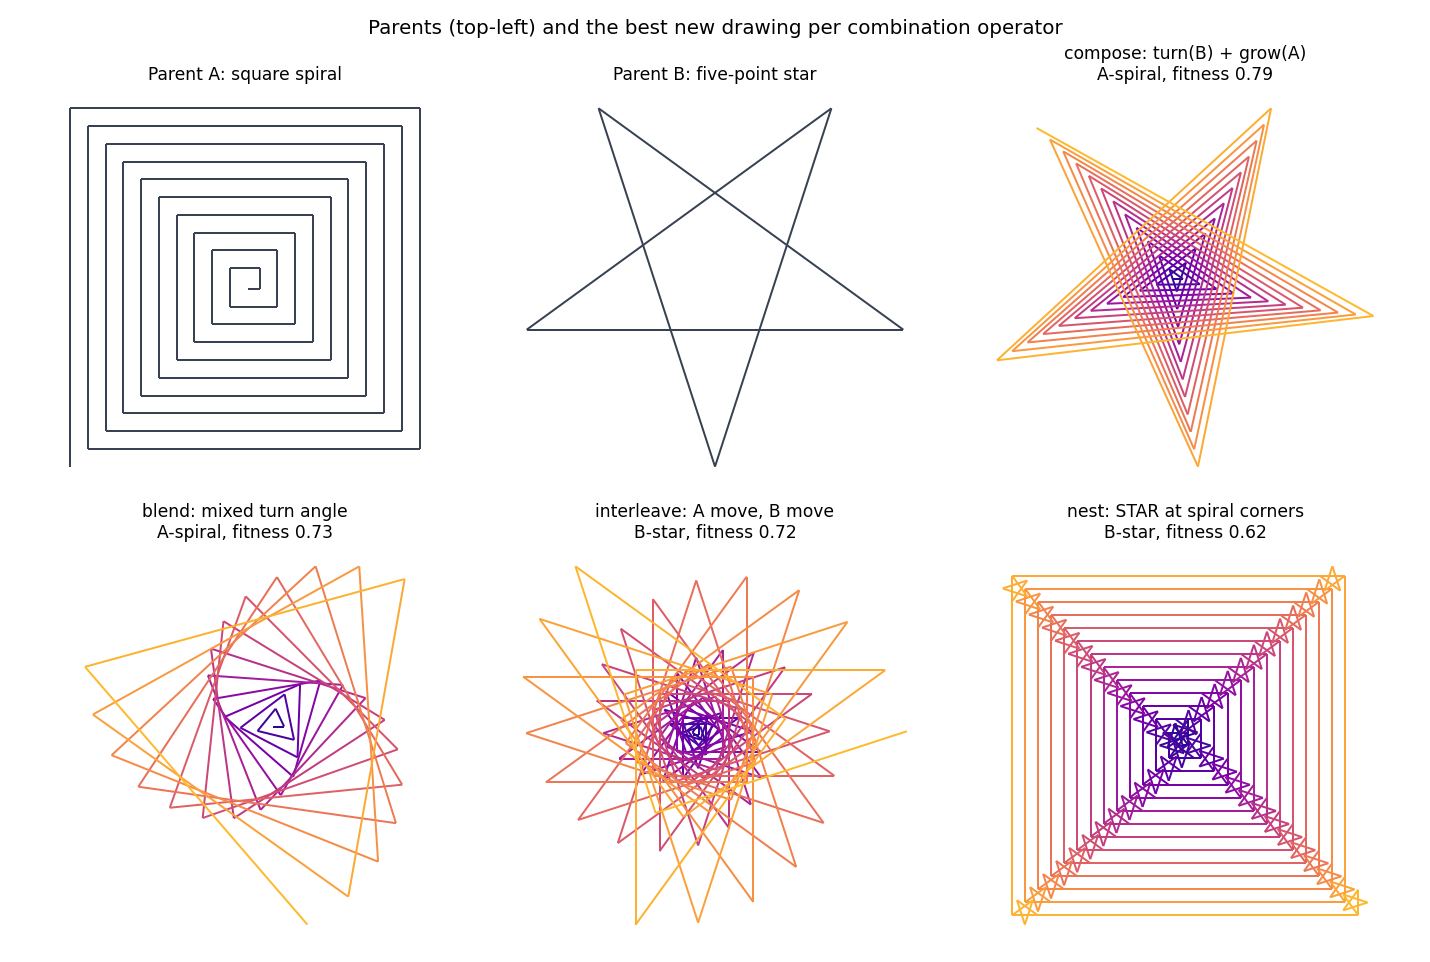

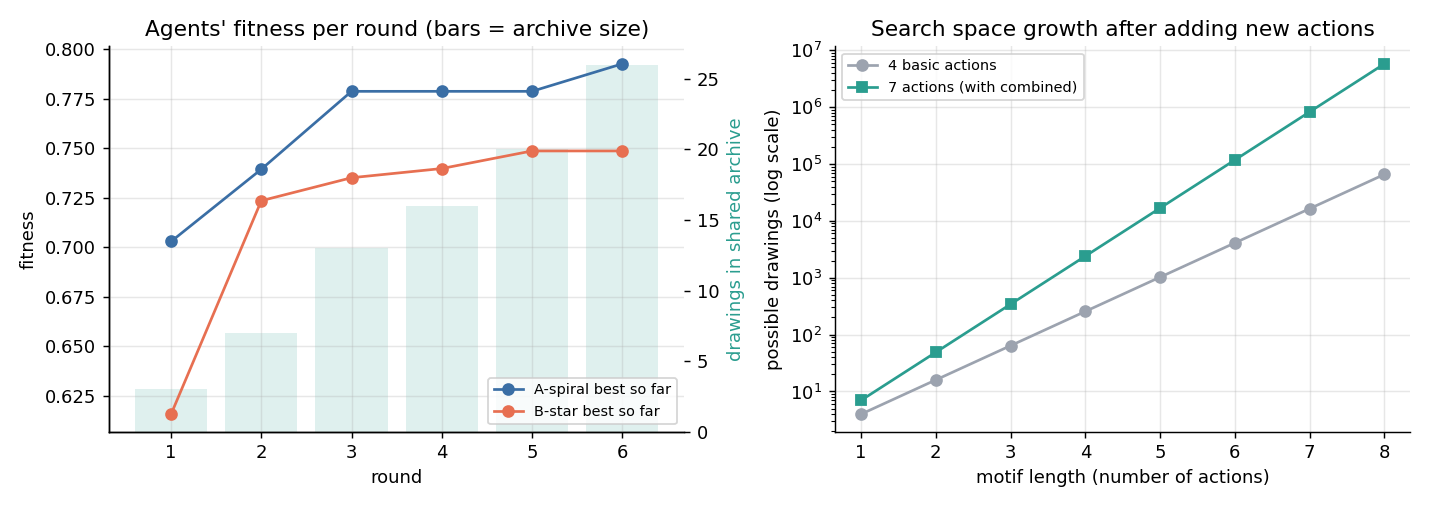

In [2]:
from IPython.display import Image, display
import glob
for p in sorted(glob.glob('images/q08_chart*.png')):
    display(Image(p))